唐的练习项目01-知识蒸馏（一）

一.运行环境检查

In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("GPU 可用:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("当前未连接 GPU，请检查运行时设置。")

PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
GPU 可用: True
GPU: Tesla T4


二.统一实验设置

In [2]:
import random
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 0.001

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # 尽量减少重复运行时的随机差异
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("训练设备:", device)
print("随机种子:", SEED)
print("Batch size:", BATCH_SIZE)

训练设备: cuda
随机种子: 42
Batch size: 128


三.下载完整数据并划分

In [3]:
# 沿用官方教程的预处理；本轮不增加数据增强
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

full_train_dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

# 每类留出 500 张做验证，保证验证集类别均衡
targets = np.array(full_train_dataset.targets)
rng = np.random.default_rng(SEED)

train_indices = []
val_indices = []

for class_id in range(10):
    indices = np.flatnonzero(targets == class_id)
    rng.shuffle(indices)
    val_indices.extend(indices[:500].tolist())
    train_indices.extend(indices[500:].tolist())

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_train_dataset, val_indices)

# 每次调用都从相同的数据打乱起点开始，供后续各组实验使用
def make_train_loader():
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=(device.type == "cuda"),
        generator=generator,
    )

train_loader = make_train_loader()

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)

assert len(set(train_indices) & set(val_indices)) == 0
assert len(train_dataset) + len(val_dataset) == 50000

print("训练集:", len(train_dataset))
print("验证集:", len(val_dataset))
print("测试集:", len(test_dataset))
print("验证集各类数量:", np.bincount(targets[val_indices]))

100%|██████████| 170M/170M [15:51<00:00, 179kB/s]


训练集: 45000
验证集: 5000
测试集: 10000
验证集各类数量: [500 500 500 500 500 500 500 500 500 500]


四.检查图片和输入形状

图片形状: (8, 3, 32, 32)
标签形状: (8,)
类别名称: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


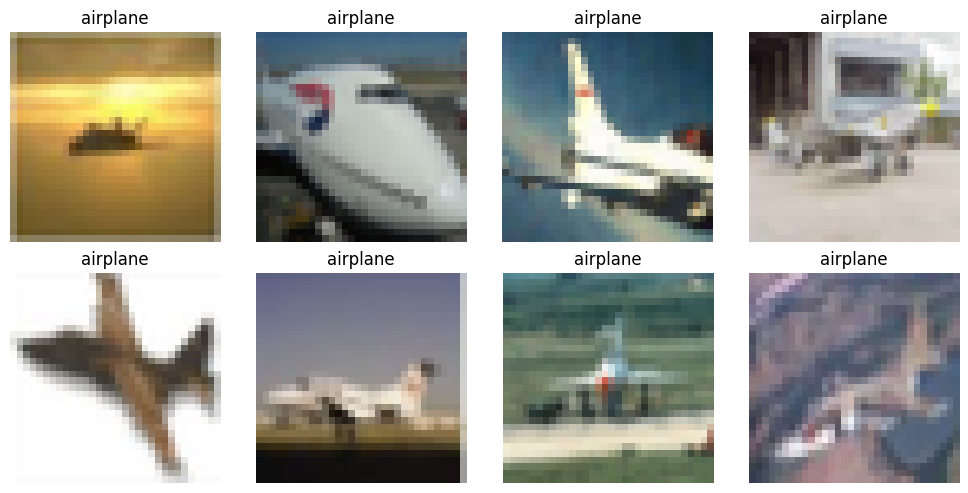

In [4]:
import matplotlib.pyplot as plt

# 单独用于检查，不消耗训练加载器的随机顺序
preview_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=False, num_workers=0
)
images, labels = next(iter(preview_loader))

print("图片形状:", tuple(images.shape))
print("标签形状:", tuple(labels.shape))
print("类别名称:", full_train_dataset.classes)

# 将归一化后的图片恢复到显示范围
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for ax, img, label in zip(axes.flat, images, labels):
    img = (img * std + mean).clamp(0, 1)
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(full_train_dataset.classes[label.item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

五.定义教师与学生模型

In [5]:
import torch.nn as nn

# 官方教师模型
class DeepNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Linear(2048, 512),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


# 官方学生模型
class LightNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


# 检查参数量和输出形状
set_seed()
teacher = DeepNN().to(device)
student_check = LightNN().to(device)

print("教师参数量:", f"{sum(p.numel() for p in teacher.parameters()):,}")
print("学生参数量:", f"{sum(p.numel() for p in student_check.parameters()):,}")

with torch.no_grad():
    dummy_images = torch.zeros(2, 3, 32, 32, device=device)
    print("教师输出形状:", tuple(teacher(dummy_images).shape))
    print("学生输出形状:", tuple(student_check(dummy_images).shape))

del student_check

教师参数量: 1,186,986
学生参数量: 267,738
教师输出形状: (2, 10)
学生输出形状: (2, 10)


六.定义训练和验证函数

In [11]:
import time
from pathlib import Path
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100 * correct / total


def train_supervised(
    model, loader, val_loader, epochs, learning_rate, run_name
):
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    best_val_accuracy = -1.0

    checkpoint_path = Path(f"/content/KD_outputs/{run_name}_best.pt")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

    for epoch in range(epochs):
        start = time.perf_counter()
        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_accuracy = 100 * correct / total
        val_loss, val_accuracy = evaluate(model, val_loader)
        seconds = time.perf_counter() - start

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "seconds": seconds,
        })

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            torch.save(model.state_dict(), checkpoint_path)
            best_mark = " ← 已保存最佳模型"
        else:
            best_mark = ""

        print(
            f"Epoch {epoch + 1:02d}/{epochs} | "
            f"训练损失 {train_loss:.4f} | "
            f"训练准确率 {train_accuracy:.2f}% | "
            f"验证损失 {val_loss:.4f} | "
            f"验证准确率 {val_accuracy:.2f}% | "
            f"{seconds:.1f}秒"
            f"{best_mark}",
            flush=True,
        )

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    model.eval()

    print(f"\n{run_name} 最佳验证准确率: {best_val_accuracy:.2f}%")
    print("模型保存位置:", checkpoint_path)
    return history


print("训练与验证函数已定义，可以运行普通学生训练单元格。")

训练与验证函数已定义，可以运行普通学生训练单元格。


七.训练教师模型

In [8]:
import json

assert device.type == "cuda", "当前没有使用 GPU，请先检查 Colab 运行时。"

# 从固定起点重新创建教师，避免重复运行时接着旧权重训练
set_seed()
teacher = DeepNN().to(device)
train_loader = make_train_loader()

teacher_history = train_supervised(
    model=teacher,
    loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    run_name="teacher",
)

with open("/content/KD_outputs/teacher_history.json", "w") as f:
    json.dump(teacher_history, f, indent=2)

print("训练记录已保存。")

Epoch 01/10 | 训练损失 1.3968 | 训练准确率 49.50% | 验证损失 1.0505 | 验证准确率 62.90% | 13.2秒 ← 已保存最佳模型
Epoch 02/10 | 训练损失 0.9523 | 训练准确率 66.36% | 验证损失 0.9053 | 验证准确率 68.48% | 13.3秒 ← 已保存最佳模型
Epoch 03/10 | 训练损失 0.7470 | 训练准确率 73.86% | 验证损失 0.7551 | 验证准确率 73.74% | 12.8秒 ← 已保存最佳模型
Epoch 04/10 | 训练损失 0.5931 | 训练准确率 79.14% | 验证损失 0.6977 | 验证准确率 75.48% | 12.9秒 ← 已保存最佳模型
Epoch 05/10 | 训练损失 0.4569 | 训练准确率 83.95% | 验证损失 0.7292 | 验证准确率 75.94% | 12.8秒 ← 已保存最佳模型
Epoch 06/10 | 训练损失 0.3331 | 训练准确率 88.08% | 验证损失 0.7932 | 验证准确率 76.20% | 13.0秒 ← 已保存最佳模型
Epoch 07/10 | 训练损失 0.2449 | 训练准确率 91.33% | 验证损失 0.8388 | 验证准确率 75.62% | 13.1秒
Epoch 08/10 | 训练损失 0.1809 | 训练准确率 93.58% | 验证损失 1.0876 | 验证准确率 75.54% | 13.0秒
Epoch 09/10 | 训练损失 0.1437 | 训练准确率 94.91% | 验证损失 1.1110 | 验证准确率 75.68% | 13.0秒
Epoch 10/10 | 训练损失 0.1246 | 训练准确率 95.67% | 验证损失 1.0785 | 验证准确率 75.40% | 13.0秒

最佳教师验证准确率: 76.20%
模型保存位置: /content/KD_outputs/teacher_best.pt
训练记录已保存。


八.为学生设置共同的起点

In [9]:
import copy

# 为三个学生保存完全相同的初始权重
set_seed()
student_initial = LightNN()
student_initial_state = copy.deepcopy(student_initial.state_dict())

torch.save(
    student_initial_state,
    "/content/KD_outputs/student_initial.pt",
)

del student_initial

print("学生初始权重已保存，普通学生和两个蒸馏学生将共用它。")

学生初始权重已保存，普通学生和两个蒸馏学生将共用它。


九.训练普通的学生作为参照

In [12]:
set_seed()

student_ce = LightNN().to(device)
student_ce.load_state_dict(student_initial_state)

# 从相同的数据打乱起点开始
train_loader = make_train_loader()

student_ce_history = train_supervised(
    model=student_ce,
    loader=train_loader,
    val_loader=val_loader,
    epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    run_name="student_ce",
)

with open("/content/KD_outputs/student_ce_history.json", "w") as f:
    json.dump(student_ce_history, f, indent=2)

print("普通学生训练记录已保存。")

Epoch 01/10 | 训练损失 1.4862 | 训练准确率 46.48% | 验证损失 1.2484 | 验证准确率 55.32% | 11.6秒 ← 已保存最佳模型
Epoch 02/10 | 训练损失 1.1746 | 训练准确率 57.95% | 验证损失 1.1175 | 验证准确率 59.20% | 10.9秒 ← 已保存最佳模型
Epoch 03/10 | 训练损失 1.0442 | 训练准确率 62.70% | 验证损失 1.0458 | 验证准确率 63.56% | 11.1秒 ← 已保存最佳模型
Epoch 04/10 | 训练损失 0.9495 | 训练准确率 66.59% | 验证损失 0.9741 | 验证准确率 65.98% | 11.4秒 ← 已保存最佳模型
Epoch 05/10 | 训练损失 0.8653 | 训练准确率 69.36% | 验证损失 0.9222 | 验证准确率 67.32% | 10.9秒 ← 已保存最佳模型
Epoch 06/10 | 训练损失 0.8003 | 训练准确率 71.95% | 验证损失 0.9184 | 验证准确率 67.78% | 11.3秒 ← 已保存最佳模型
Epoch 07/10 | 训练损失 0.7418 | 训练准确率 73.86% | 验证损失 0.9155 | 验证准确率 67.68% | 11.2秒
Epoch 08/10 | 训练损失 0.6808 | 训练准确率 76.03% | 验证损失 0.8527 | 验证准确率 69.62% | 10.9秒 ← 已保存最佳模型
Epoch 09/10 | 训练损失 0.6180 | 训练准确率 78.30% | 验证损失 0.8752 | 验证准确率 69.76% | 10.8秒 ← 已保存最佳模型
Epoch 10/10 | 训练损失 0.5691 | 训练准确率 80.09% | 验证损失 0.8793 | 验证准确率 70.34% | 11.0秒 ← 已保存最佳模型

student_ce 最佳验证准确率: 70.34%
模型保存位置: /content/KD_outputs/student_ce_best.pt
普通学生训练记录已保存。


# 十.定义蒸馏训练函数

In [13]:
import json
import torch.nn.functional as F

def train_distillation(
    teacher, student, loader, val_loader,
    epochs, learning_rate, temperature, run_name,
    alpha=0.25,
):
    optimizer = optim.Adam(student.parameters(), lr=learning_rate)
    history = []
    best_val_accuracy = -1.0

    checkpoint_path = Path(f"/content/KD_outputs/{run_name}_best.pt")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

    teacher.eval()

    for epoch in range(epochs):
        start = time.perf_counter()
        student.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # 教师只提供指导，不参与参数更新
            with torch.no_grad():
                teacher_logits = teacher(images)

            optimizer.zero_grad()
            student_logits = student(images)

            # 学习真实标签
            ce_loss = criterion(student_logits, labels)

            # 学习教师在温度 T 下的类别概率分布
            kd_loss = F.kl_div(
                F.log_softmax(student_logits / temperature, dim=1),
                F.softmax(teacher_logits / temperature, dim=1),
                reduction="batchmean",
            ) * temperature**2

            loss = (1 - alpha) * ce_loss + alpha * kd_loss

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (
                student_logits.argmax(dim=1) == labels
            ).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_accuracy = 100 * correct / total

        # 验证仍用真实标签的交叉熵和准确率
        val_loss, val_accuracy = evaluate(student, val_loader)
        seconds = time.perf_counter() - start

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "seconds": seconds,
            "temperature": temperature,
            "alpha": alpha,
        })

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            torch.save(student.state_dict(), checkpoint_path)
            best_mark = " ← 已保存最佳模型"
        else:
            best_mark = ""

        print(
            f"{run_name} | Epoch {epoch + 1:02d}/{epochs} | "
            f"训练总损失 {train_loss:.4f} | "
            f"训练准确率 {train_accuracy:.2f}% | "
            f"验证损失 {val_loss:.4f} | "
            f"验证准确率 {val_accuracy:.2f}% | "
            f"{seconds:.1f}秒"
            f"{best_mark}",
            flush=True,
        )

    student.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    student.eval()

    with open(f"/content/KD_outputs/{run_name}_history.json", "w") as f:
        json.dump(history, f, indent=2)

    print(f"\n{run_name} 最佳验证准确率: {best_val_accuracy:.2f}%\n")
    return history


print("蒸馏训练函数已定义。")

蒸馏训练函数已定义。


# 十一.两个不同的温度下的蒸馏训练

In [14]:
assert device.type == "cuda", "请先确认 Colab 已连接 GPU。"

# 明确使用验证准确率最高的教师
teacher.load_state_dict(
    torch.load(
        "/content/KD_outputs/teacher_best.pt",
        map_location=device,
        weights_only=True,
    )
)
teacher.to(device)
teacher.eval()

# 读取尚未训练的公共学生初始权重
initial_state = torch.load(
    "/content/KD_outputs/student_initial.pt",
    map_location="cpu",
    weights_only=True,
)

kd_models = {}
kd_histories = {}

for temperature in [2, 4]:
    run_name = f"student_kd_T{temperature}"
    print(f"\n开始实验：{run_name}")

    # 与普通学生一样：设置种子、创建模型、载入公共初始权重
    set_seed()
    student = LightNN().to(device)
    student.load_state_dict(initial_state)
    train_loader = make_train_loader()

    history = train_distillation(
        teacher=teacher,
        student=student,
        loader=train_loader,
        val_loader=val_loader,
        epochs=EPOCHS,
        learning_rate=LEARNING_RATE,
        temperature=temperature,
        run_name=run_name,
        alpha=0.25,
    )

    kd_models[temperature] = student
    kd_histories[temperature] = history

print("验证集结果汇总")
print("-" * 35)

ce_best = max(row["val_accuracy"] for row in student_ce_history)
print(f"普通学生 CE: {ce_best:.2f}%")

for temperature in [2, 4]:
    best = max(
        row["val_accuracy"] for row in kd_histories[temperature]
    )
    print(
        f"蒸馏学生 T={temperature}: {best:.2f}%"
        f"（相对 CE：{best - ce_best:+.2f} 个百分点）"
    )


开始实验：student_kd_T2
student_kd_T2 | Epoch 01/10 | 训练总损失 2.0367 | 训练准确率 46.26% | 验证损失 1.2408 | 验证准确率 55.64% | 12.0秒 ← 已保存最佳模型
student_kd_T2 | Epoch 02/10 | 训练总损失 1.5482 | 训练准确率 57.92% | 验证损失 1.1454 | 验证准确率 58.86% | 11.7秒 ← 已保存最佳模型
student_kd_T2 | Epoch 03/10 | 训练总损失 1.3396 | 训练准确率 62.66% | 验证损失 1.0696 | 验证准确率 63.44% | 11.5秒 ← 已保存最佳模型
student_kd_T2 | Epoch 04/10 | 训练总损失 1.1970 | 训练准确率 66.37% | 验证损失 1.0084 | 验证准确率 65.32% | 11.6秒 ← 已保存最佳模型
student_kd_T2 | Epoch 05/10 | 训练总损失 1.0757 | 训练准确率 69.40% | 验证损失 0.9562 | 验证准确率 66.70% | 11.6秒 ← 已保存最佳模型
student_kd_T2 | Epoch 06/10 | 训练总损失 0.9844 | 训练准确率 71.80% | 验证损失 0.9280 | 验证准确率 68.78% | 11.6秒 ← 已保存最佳模型
student_kd_T2 | Epoch 07/10 | 训练总损失 0.9075 | 训练准确率 73.68% | 验证损失 0.8943 | 验证准确率 69.58% | 11.7秒 ← 已保存最佳模型
student_kd_T2 | Epoch 08/10 | 训练总损失 0.8311 | 训练准确率 76.24% | 验证损失 0.8690 | 验证准确率 70.40% | 11.6秒 ← 已保存最佳模型
student_kd_T2 | Epoch 09/10 | 训练总损失 0.7594 | 训练准确率 77.96% | 验证损失 0.9039 | 验证准确率 70.88% | 11.7秒 ← 已保存最佳模型
student_kd_T2 | Epoch 10/10 | 训练总损失

十二.读取最佳权重

In [15]:
import pandas as pd
from pathlib import Path

output_dir = Path("/content/KD_outputs")

# 温度已根据验证集选定，测试阶段不再更改
SELECTED_T = 4

experiments = [
    ("Teacher", DeepNN, "teacher_best.pt", teacher_history),
    ("Student CE", LightNN, "student_ce_best.pt", student_ce_history),
    (
        "Student KD T=4",
        LightNN,
        "student_kd_T4_best.pt",
        kd_histories[SELECTED_T],
    ),
]

rows = []

for name, model_class, filename, history in experiments:
    model = model_class().to(device)
    model.load_state_dict(
        torch.load(
            output_dir / filename,
            map_location=device,
            weights_only=True,
        )
    )

    test_loss, test_accuracy = evaluate(model, test_loader)

    rows.append({
        "model": name,
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_val_accuracy": max(r["val_accuracy"] for r in history),
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    })

    del model

results = pd.DataFrame(rows)
results.to_csv(output_dir / "final_results.csv", index=False)

display(results.round(4))

ce_accuracy = results.loc[
    results["model"] == "Student CE", "test_accuracy"
].iloc[0]

kd_accuracy = results.loc[
    results["model"] == "Student KD T=4", "test_accuracy"
].iloc[0]

print(
    f"\nT=4 蒸馏学生相对普通学生的测试准确率变化："
    f"{kd_accuracy - ce_accuracy:+.2f} 个百分点"
)
print("结果已保存为 final_results.csv")

,model,parameters,best_val_accuracy,test_loss,test_accuracy
0,Teacher,1186986,76.20,0.8535,74.45
1,Student CE,267738,70.34,0.9251,69.21
2,Student KD T=4,267738,71.84,0.9510,70.66



T=4 蒸馏学生相对普通学生的测试准确率变化：+1.45 个百分点
结果已保存为 final_results.csv


十三.绘制三名学生的验证学习曲线

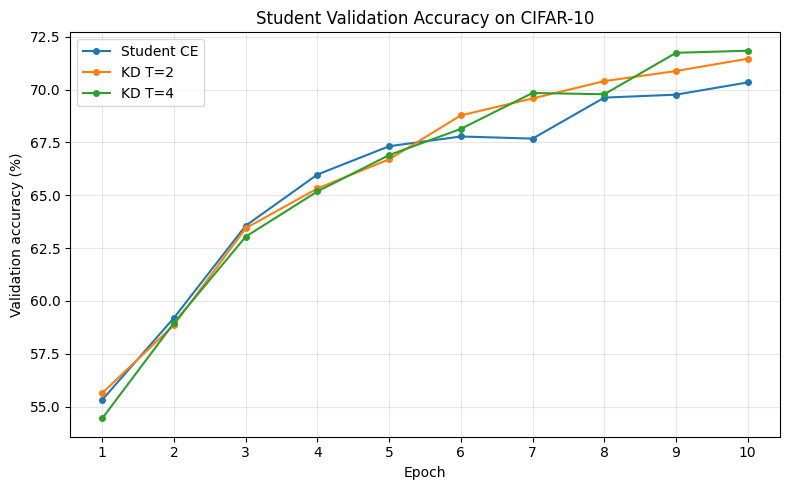

In [16]:
import matplotlib.pyplot as plt

histories = {
    "Student CE": student_ce_history,
    "KD T=2": kd_histories[2],
    "KD T=4": kd_histories[4],
}

fig, ax = plt.subplots(figsize=(8, 5))

for name, history in histories.items():
    ax.plot(
        [r["epoch"] for r in history],
        [r["val_accuracy"] for r in history],
        marker="o",
        markersize=4,
        label=name,
    )

ax.set(
    title="Student Validation Accuracy on CIFAR-10",
    xlabel="Epoch",
    ylabel="Validation accuracy (%)",
)
ax.set_xticks(range(1, EPOCHS + 1))
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(
    output_dir / "validation_accuracy.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()